In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
import string

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Semua library berhasil di-import.")

Semua library berhasil di-import.


In [2]:
import pandas as pd

fake_df = pd.read_csv('/content/Fake.csv')
true_df = pd.read_csv('/content/True.csv')

print("Jumlah data FAKE :", len(fake_df))
print("Jumlah data REAL :", len(true_df))

Jumlah data FAKE : 23481
Jumlah data REAL : 21417


In [3]:
print("Kolom Fake:", fake_df.columns.tolist())
print("Kolom True:", true_df.columns.tolist())

Kolom Fake: ['title', 'text', 'subject', 'date']
Kolom True: ['title', 'text', 'subject', 'date']


In [4]:
# Memberikan label
# 0 = FAKE
# 1 = REAL

fake_df['label'] = 0
true_df['label'] = 1

print("Label FAKE :", fake_df['label'].unique())
print("Label REAL :", true_df['label'].unique())

Label FAKE : [0]
Label REAL : [1]


In [5]:
# Menggabungkan dataset FAKE dan REAL

df = pd.concat(
    [fake_df, true_df],
    ignore_index=True
)

print("Total dataset :", len(df))

Total dataset : 44898


In [6]:
df = df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

display(df.head())

,title,text,subject,date,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,"21st Century Wire says Ben Stein, reputable pr...",US_News,"February 13, 2017",0
1,Trump drops Steve Bannon from National Securit...,WASHINGTON (Reuters) - U.S. President Donald T...,politicsNews,"April 5, 2017",1
2,Puerto Rico expects U.S. to lift Jones Act shi...,(Reuters) - Puerto Rico Governor Ricardo Rosse...,politicsNews,"September 27, 2017",1
3,OOPS: Trump Just Accidentally Confirmed He Le...,"On Monday, Donald Trump once again embarrassed...",News,"May 22, 2017",0
4,Donald Trump heads for Scotland to reopen a go...,"GLASGOW, Scotland (Reuters) - Most U.S. presid...",politicsNews,"June 24, 2016",1


In [7]:
print(df['label'].value_counts())

label
0    23481
1    21417
Name: count, dtype: int64


In [8]:
print("Data kosong:")
print(df.isnull().sum())

Data kosong:
title      0
text       0
subject    0
date       0
label      0
dtype: int64


In [9]:
print("Jumlah data duplikat :", df.duplicated().sum())

Jumlah data duplikat : 209


In [10]:
# Menghapus data duplikat
df = df.drop_duplicates().reset_index(drop=True)

print("Jumlah data setelah menghapus duplikat :", len(df))
print("Jumlah duplikat tersisa :", df.duplicated().sum())

Jumlah data setelah menghapus duplikat : 44689
Jumlah duplikat tersisa : 0


In [11]:
print(df['label'].value_counts())

label
0    23478
1    21211
Name: count, dtype: int64


In [12]:
# Menggabungkan judul dan isi berita
df['content'] = df['title'].astype(str) + ' ' + df['text'].astype(str)

display(df[['title', 'text', 'content', 'label']].head())

,title,text,content,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,"21st Century Wire says Ben Stein, reputable pr...",Ben Stein Calls Out 9th Circuit Court: Committ...,0
1,Trump drops Steve Bannon from National Securit...,WASHINGTON (Reuters) - U.S. President Donald T...,Trump drops Steve Bannon from National Securit...,1
2,Puerto Rico expects U.S. to lift Jones Act shi...,(Reuters) - Puerto Rico Governor Ricardo Rosse...,Puerto Rico expects U.S. to lift Jones Act shi...,1
3,OOPS: Trump Just Accidentally Confirmed He Le...,"On Monday, Donald Trump once again embarrassed...",OOPS: Trump Just Accidentally Confirmed He Le...,0
4,Donald Trump heads for Scotland to reopen a go...,"GLASGOW, Scotland (Reuters) - Most U.S. presid...",Donald Trump heads for Scotland to reopen a go...,1


In [13]:
def clean_text(text):
    # Ubah menjadi lowercase
    text = str(text).lower()

    # Hapus URL
    text = re.sub(r'http\S+|www\S+', ' ', text)

    # Hapus HTML
    text = re.sub(r'<.*?>', ' ', text)

    # Hapus angka
    text = re.sub(r'\d+', ' ', text)

    # Hapus tanda baca
    text = text.translate(
        str.maketrans('', '', string.punctuation)
    )

    # Hapus spasi berlebih
    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [14]:
df['clean_text'] = df['content'].apply(clean_text)

print("Preprocessing selesai.")

Preprocessing selesai.


In [15]:
print("SEBELUM:")
print(df['content'].iloc[0])

print("\nSESUDAH:")
print(df['clean_text'].iloc[0])

SEBELUM:
Ben Stein Calls Out 9th Circuit Court: Committed a ‘Coup d’état’ Against the Constitution 21st Century Wire says Ben Stein, reputable professor from, Pepperdine University (also of some Hollywood fame appearing in TV shows and films such as Ferris Bueller s Day Off) made some provocative statements on Judge Jeanine Pirro s show recently. While discussing the halt that was imposed on President Trump s Executive Order on travel. Stein referred to the judgement by the 9th Circuit Court in Washington state as a  Coup d tat against the executive branch and against the constitution.  Stein went on to call the Judges in Seattle  political puppets  and the judiciary  political pawns. Watch the interview below for the complete statements and note the stark contrast to the rhetoric of the leftist media and pundits who neglect to note that no court has ever blocked any Presidential orders in immigration in the past or discuss the legal efficacy of the halt or the actual text of the Execu

In [16]:
def clean_text(text):
    # Ubah ke string dan lowercase
    text = str(text).lower()

    # Hapus URL
    text = re.sub(r'http\S+|www\S+', ' ', text)

    # Hapus HTML
    text = re.sub(r'<.*?>', ' ', text)

    # Hapus penanda sumber Reuters
    text = re.sub(r'\breuters\b', ' ', text)

    # Hapus angka
    text = re.sub(r'\d+', ' ', text)

    # Hapus tanda baca
    text = text.translate(
        str.maketrans('', '', string.punctuation)
    )

    # Hapus spasi berlebih
    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [17]:
df['clean_text'] = df['content'].apply(clean_text)

print("Preprocessing selesai.")

Preprocessing selesai.


In [18]:
print("Jumlah teks kosong:",
      (df['clean_text'].str.strip() == '').sum())

Jumlah teks kosong: 9


In [19]:
# Hapus data yang hasil preprocessing-nya kosong
df = df[df['clean_text'].str.strip() != ''].reset_index(drop=True)

print("Jumlah data setelah menghapus teks kosong :", len(df))
print(
    "Jumlah teks kosong tersisa :",
    (df['clean_text'].str.strip() == '').sum()
)

Jumlah data setelah menghapus teks kosong : 44680
Jumlah teks kosong tersisa : 0


In [20]:
label_counts = df['label'].value_counts().sort_index()

print("FAKE :", label_counts.get(0, 0))
print("REAL :", label_counts.get(1, 0))

FAKE : 23469
REAL : 21211


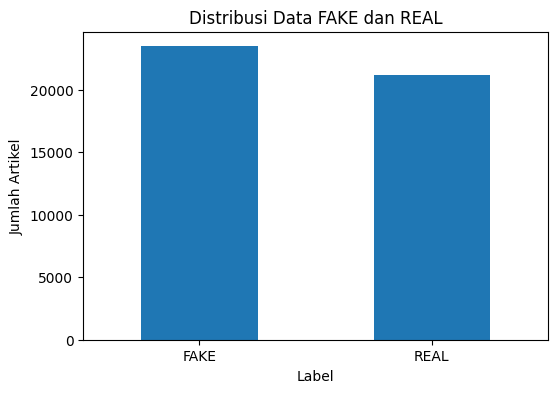

In [21]:
label_counts.plot(
    kind='bar',
    figsize=(6, 4)
)

plt.title('Distribusi Data FAKE dan REAL')
plt.xlabel('Label')
plt.ylabel('Jumlah Artikel')
plt.xticks(
    [0, 1],
    ['FAKE', 'REAL'],
    rotation=0
)

plt.show()

In [22]:
X = df['clean_text']
y = df['label']

print("Jumlah data :", len(X))

Jumlah data : 44680


In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data training :", len(X_train))
print("Jumlah data testing  :", len(X_test))

Jumlah data training : 35744
Jumlah data testing  : 8936


In [24]:
print("Distribusi Training:")
print(y_train.value_counts())

print("\nDistribusi Testing:")
print(y_test.value_counts())

Distribusi Training:
label
0    18775
1    16969
Name: count, dtype: int64

Distribusi Testing:
label
0    4694
1    4242
Name: count, dtype: int64


In [25]:
tfidf = TfidfVectorizer(
    stop_words='english',
    max_df=0.7,
    max_features=50000
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF selesai.")
print("Shape data training :", X_train_tfidf.shape)
print("Shape data testing  :", X_test_tfidf.shape)

TF-IDF selesai.
Shape data training : (35744, 50000)
Shape data testing  : (8936, 50000)


In [26]:
tfidf.fit_transform(X_train)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 5238620 stored elements and shape (35744, 50000)>

In [27]:
print("Jumlah vocabulary :", len(tfidf.vocabulary_))

Jumlah vocabulary : 50000


In [28]:
feature_names = tfidf.get_feature_names_out()

print("Contoh fitur TF-IDF:")
print(feature_names[:30])

Contoh fitur TF-IDF:
['aa' 'aaa' 'aab' 'aadhaar' 'aadl' 'aaf' 'aalo' 'aamer' 'aapl' 'aaplo'
 'aardvark' 'aaron' 'aaronson' 'aarp' 'ab' 'aba' 'abaaoud' 'ababa'
 'abacha' 'aback' 'abad' 'abadi' 'abandon' 'abandoned' 'abandoning'
 'abandonment' 'abandons' 'abarrel' 'abas' 'abasaslani']


In [29]:
tfidf = TfidfVectorizer(
    stop_words='english',
    max_df=0.7,
    max_features=50000
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF selesai.")
print("Shape data training :", X_train_tfidf.shape)
print("Shape data testing  :", X_test_tfidf.shape)

TF-IDF selesai.
Shape data training : (35744, 50000)
Shape data testing  : (8936, 50000)


In [30]:
# MODEL 1 - Multinomial Naive Bayes

nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

nb_pred = nb_model.predict(X_test_tfidf)

print("Training Naive Bayes selesai.")

Training Naive Bayes selesai.


In [31]:
nb_accuracy = accuracy_score(y_test, nb_pred)
nb_precision = precision_score(y_test, nb_pred)
nb_recall = recall_score(y_test, nb_pred)
nb_f1 = f1_score(y_test, nb_pred)

print("=== HASIL NAIVE BAYES ===")
print(f"Accuracy  : {nb_accuracy:.4f}")
print(f"Precision : {nb_precision:.4f}")
print(f"Recall    : {nb_recall:.4f}")
print(f"F1-Score  : {nb_f1:.4f}")

=== HASIL NAIVE BAYES ===
Accuracy  : 0.9349
Precision : 0.9355
Recall    : 0.9267
F1-Score  : 0.9311


In [32]:
print(classification_report(
    y_test,
    nb_pred,
    target_names=['FAKE', 'REAL']
))

              precision    recall  f1-score   support

        FAKE       0.93      0.94      0.94      4694
        REAL       0.94      0.93      0.93      4242

    accuracy                           0.93      8936
   macro avg       0.93      0.93      0.93      8936
weighted avg       0.93      0.93      0.93      8936



In [33]:
nb_cm = confusion_matrix(y_test, nb_pred)

print("Confusion Matrix:")
print(nb_cm)

Confusion Matrix:
[[4423  271]
 [ 311 3931]]


In [34]:
# MODEL 2 - Logistic Regression

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_tfidf, y_train)

lr_pred = lr_model.predict(X_test_tfidf)

print("Training Logistic Regression selesai.")

Training Logistic Regression selesai.


In [35]:
lr_accuracy = accuracy_score(y_test, lr_pred)
lr_precision = precision_score(y_test, lr_pred)
lr_recall = recall_score(y_test, lr_pred)
lr_f1 = f1_score(y_test, lr_pred)

print("=== HASIL LOGISTIC REGRESSION ===")
print(f"Accuracy  : {lr_accuracy:.4f}")
print(f"Precision : {lr_precision:.4f}")
print(f"Recall    : {lr_recall:.4f}")
print(f"F1-Score  : {lr_f1:.4f}")

=== HASIL LOGISTIC REGRESSION ===
Accuracy  : 0.9794
Precision : 0.9761
Recall    : 0.9807
F1-Score  : 0.9784


In [36]:
print(classification_report(
    y_test,
    lr_pred,
    target_names=['FAKE', 'REAL']
))

              precision    recall  f1-score   support

        FAKE       0.98      0.98      0.98      4694
        REAL       0.98      0.98      0.98      4242

    accuracy                           0.98      8936
   macro avg       0.98      0.98      0.98      8936
weighted avg       0.98      0.98      0.98      8936



In [37]:
lr_cm = confusion_matrix(y_test, lr_pred)

print("Confusion Matrix:")
print(lr_cm)

Confusion Matrix:
[[4592  102]
 [  82 4160]]


In [38]:
# MODEL 3 - Linear SVM

svm_model = LinearSVC(
    random_state=42
)

svm_model.fit(X_train_tfidf, y_train)

svm_pred = svm_model.predict(X_test_tfidf)

print("Training Linear SVM selesai.")

Training Linear SVM selesai.


In [39]:
svm_accuracy = accuracy_score(y_test, svm_pred)
svm_precision = precision_score(y_test, svm_pred)
svm_recall = recall_score(y_test, svm_pred)
svm_f1 = f1_score(y_test, svm_pred)

print("=== HASIL LINEAR SVM ===")
print(f"Accuracy  : {svm_accuracy:.4f}")
print(f"Precision : {svm_precision:.4f}")
print(f"Recall    : {svm_recall:.4f}")
print(f"F1-Score  : {svm_f1:.4f}")

=== HASIL LINEAR SVM ===
Accuracy  : 0.9895
Precision : 0.9885
Recall    : 0.9894
F1-Score  : 0.9889


In [40]:
print(classification_report(
    y_test,
    svm_pred,
    target_names=['FAKE', 'REAL']
))

              precision    recall  f1-score   support

        FAKE       0.99      0.99      0.99      4694
        REAL       0.99      0.99      0.99      4242

    accuracy                           0.99      8936
   macro avg       0.99      0.99      0.99      8936
weighted avg       0.99      0.99      0.99      8936



In [41]:
svm_cm = confusion_matrix(y_test, svm_pred)

print("Confusion Matrix:")
print(svm_cm)

Confusion Matrix:
[[4645   49]
 [  45 4197]]


In [42]:
results = pd.DataFrame({
    'Model': [
        'Naive Bayes',
        'Logistic Regression',
        'Linear SVM'
    ],
    'Accuracy': [
        nb_accuracy,
        lr_accuracy,
        svm_accuracy
    ],
    'Precision': [
        nb_precision,
        lr_precision,
        svm_precision
    ],
    'Recall': [
        nb_recall,
        lr_recall,
        svm_recall
    ],
    'F1-Score': [
        nb_f1,
        lr_f1,
        svm_f1
    ]
})

results

,Model,Accuracy,Precision,Recall,F1-Score
0,Naive Bayes,0.934870,0.935507,0.926686,0.931075
1,Logistic Regression,0.979409,0.976068,0.980669,0.978363
2,Linear SVM,0.989481,0.988460,0.989392,0.988926


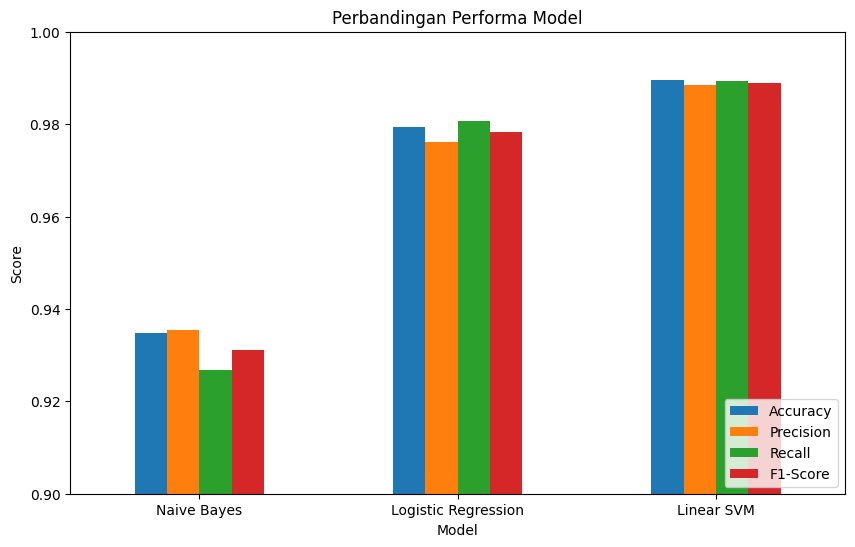

In [43]:
results_plot = results.set_index('Model')

results_plot.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Perbandingan Performa Model')
plt.ylabel('Score')
plt.xlabel('Model')
plt.ylim(0.9, 1.0)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

In [44]:
import joblib

joblib.dump(
    svm_model,
    '/content/fake_news_svm_model.pkl'
)

joblib.dump(
    tfidf,
    '/content/tfidf_vectorizer.pkl'
)

print("Model dan TF-IDF berhasil disimpan.")

Model dan TF-IDF berhasil disimpan.


In [45]:
def predict_news(title, text):
    content = str(title) + ' ' + str(text)

    cleaned = clean_text(content)

    vector = tfidf.transform([cleaned])

    prediction = svm_model.predict(vector)[0]

    if prediction == 0:
        return "FAKE NEWS"
    else:
        return "REAL NEWS"

In [46]:
title = """
Government announces new education policy
"""

text = """
The government announced a new education program
for university students during an official meeting.
"""

hasil = predict_news(title, text)

print("Hasil Prediksi :", hasil)

Hasil Prediksi : FAKE NEWS


In [47]:
# Menguji model menggunakan salah satu data testing

sample_index = 0

sample_text = X_test.iloc[sample_index]
actual_label = y_test.iloc[sample_index]

sample_vector = tfidf.transform([sample_text])
predicted_label = svm_model.predict(sample_vector)[0]

print("Teks:")
print(sample_text[:500])

print("\nLabel Aktual :", "FAKE" if actual_label == 0 else "REAL")
print("Prediksi     :", "FAKE" if predicted_label == 0 else "REAL")

Teks:
hawaii renews bid to narrow trump travel ban the state of hawaii renewed its bid to narrow president donald trump’s temporary travel ban following court rulings which said the state had taken the wrong procedural approach in attempts to challenge the administration’s policy earlier this week in a court filing late on friday hawaii’s attorney general asked a honolulu judge to issue an injunction allowing grandparents and other family members to travel to the united states the us supreme court las

Label Aktual : REAL
Prediksi     : REAL
